# CNN para extraer la vibración del puente desde un carro (drive-by)

**Objetivo:** entrenar una red neuronal convolucional (CNN) que reciba la aceleración medida dentro de un carro que cruza un puente y devuelva solo la vibración del puente, sin la rugosidad de la carretera, la dinámica del carro ni el ruido del teléfono. Con esa vibración se busca la frecuencia natural del puente (f1).

**Idea:** antes y después del puente se conoce el perfil de la carretera. Con esos tramos la red puede aprender cómo responde el carro. Sobre el puente el perfil se deja vacío y la red lo completa con la vibración del puente.

**Datos:** paquete `datasets/p02-five-bridges-traffic` (5 puentes para entrenar, validar y probar; 5 puentes no vistos para generalización).

## Índice

1. Librerías y configuración
2. Cargar los datos
3. Mirar un viaje
4. Preparar la entrada y la salida de la red
5. Dividir en entrenamiento, validación y prueba
6. Construir la red
7. Entrenar la red
8. Evaluar en los viajes de prueba
9. Comparar con un método sin red
10. Probar en puentes no vistos
11. Conclusiones


## 1. Librerías y configuración

Se cargan las librerías que usa el notebook:

- `numpy`: operaciones con arreglos de números (las señales son arreglos).
- `h5py`: leer los archivos de datos `.h5`.
- `matplotlib`: hacer gráficas.
- `torch` (PyTorch): construir y entrenar la red neuronal.

También se fija una **semilla** (`SEED`) para que los resultados aleatorios sean siempre los mismos, y se elige el **dispositivo**: la GPU (`cuda`) si está disponible, si no, el procesador (`cpu`).

In [1]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch

# Fixed seed so that every run gives the same random numbers
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use the GPU if there is one
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


## 2. Cargar los datos

Cada archivo `.h5` guarda muchos viajes. Un **viaje** es un carro que recorre 100 m de carretera, cruza el puente y recorre otros 100 m. En cada viaje hay varias señales, todas medidas cada 0.005 s (200 muestras por segundo).

Se usa la versión `padded`: todos los viajes tienen el mismo largo (11 000 muestras = 55 s). Los viajes más cortos se rellenan con ceros al final.

Cada señal se guarda en una tabla de números: **una fila por viaje y una columna por muestra** (1000 filas × 11 000 columnas).

Se leen solo las señales que necesita la red (Tabla 1 y Figura 1):

**Tabla 1.** Señales que se leen de cada viaje.

| Variable | Qué es | Uso |
|---|---|---|
| `measured` | aceleración medida por el teléfono dentro del carro [m/s²] | entrada |
| `road_acc` | aceleración que la rugosidad de la carretera le impone a la rueda [m/s²] | entrada (antes y después del puente) |
| `bridge_acc` | aceleración del puente en el punto donde está la rueda [m/s²] | salida que debe predecir la red |
| `segment` | 0 = antes del puente, 1 = sobre el puente, 2 = después | saber dónde está el carro |
| `valid` | 1 = muestra real, 0 = relleno con ceros | no usar el relleno |

Y tres datos de cada viaje (un número por viaje): nombre del puente (`bridge_name`), su frecuencia natural (`f1`, en Hz) y la velocidad del carro (`speed`, en m/s).

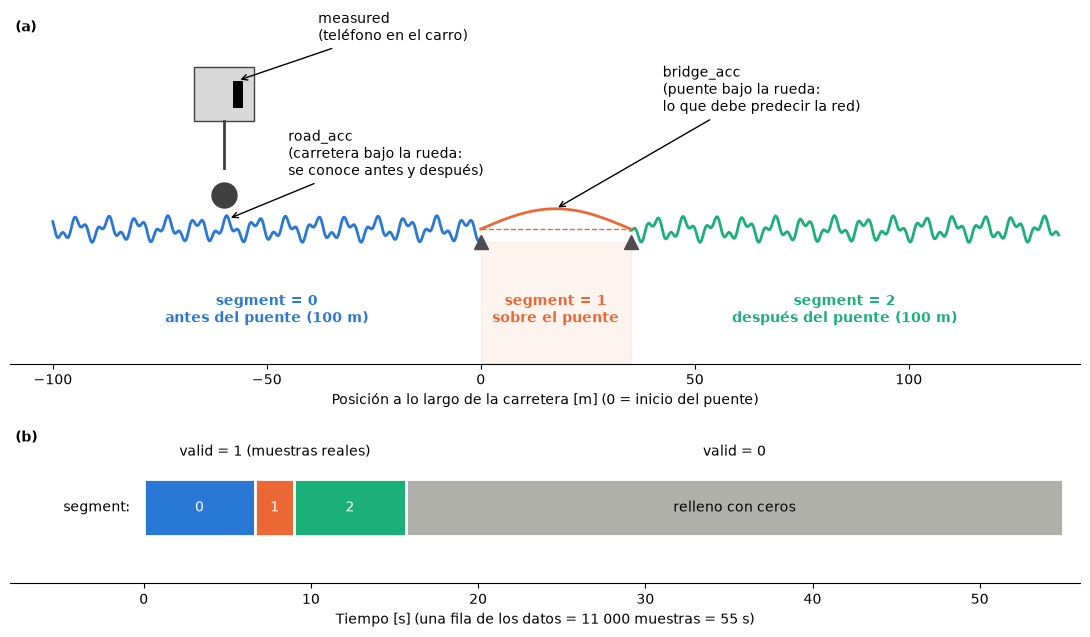

In [2]:
# Diagram only: an illustrative crossing (synthetic numbers), it does not use the data
from matplotlib.patches import Rectangle

BEFORE, BRIDGE, AFTER, PADDING = "#2a78d6", "#eb6834", "#1baf7a", "#b0b0ab"
L = 35.0      # span of the illustrated bridge [m]
v = 15.0      # speed of the illustrated car [m/s]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), height_ratios=[2.2, 1])

# (a) Side view of the crossing, along the road
x_road1 = np.linspace(-100, 0, 400)
x_road2 = np.linspace(L, L + 100, 400)
x_deck = np.linspace(0, L, 200)
rng = np.random.default_rng(SEED)
bumps = lambda x: 0.25 * np.sin(0.9 * x + rng.uniform(0, 6)) + 0.15 * np.sin(2.3 * x)   # fake roughness
ax1.plot(x_road1, bumps(x_road1), color=BEFORE, lw=2)
ax1.plot(x_road2, bumps(x_road2), color=AFTER, lw=2)
ax1.plot(x_deck, 0.6 * np.sin(np.pi * x_deck / L), color=BRIDGE, lw=2)      # deck moving (exaggerated)
ax1.plot(x_deck, np.zeros_like(x_deck), color=BRIDGE, lw=1, ls="--")        # deck at rest
ax1.plot([0, L], [-0.4, -0.4], "^", color="0.3", ms=10)                      # supports
ax1.fill_between([0, L], -4, -0.4, color=BRIDGE, alpha=0.08)

# Quarter car on the road before the bridge: wheel, spring and body with the phone
xc = -60
ax1.plot(xc, 1.0, "o", ms=18, color="0.25")
ax1.plot([xc, xc], [1.8, 3.2], color="0.25", lw=2)
ax1.add_patch(Rectangle((xc - 7, 3.2), 14, 1.6, fc="0.85", ec="0.25"))
ax1.add_patch(Rectangle((xc + 2, 3.6), 2.5, 0.8, fc="black"))

ax1.annotate("measured\n(teléfono en el carro)", (xc + 3.2, 4.4), (xc + 22, 5.6), arrowprops=dict(arrowstyle="->"))
ax1.annotate("road_acc\n(carretera bajo la rueda:\nse conoce antes y después)", (xc + 1, 0.3), (-45, 1.6),
             arrowprops=dict(arrowstyle="->"))
ax1.annotate("bridge_acc\n(puente bajo la rueda:\nlo que debe predecir la red)", (L / 2, 0.6), (L / 2 + 25, 3.5),
             arrowprops=dict(arrowstyle="->"))

# Segment of each part of the road
for x0, x1, color, text in [(-100, 0, BEFORE, "segment = 0\nantes del puente (100 m)"),
                            (0, L, BRIDGE, "segment = 1\nsobre el puente"),
                            (L, L + 100, AFTER, "segment = 2\ndespués del puente (100 m)")]:
    ax1.text((x0 + x1) / 2, -2.4, text, ha="center", va="center", color=color, fontweight="bold")
ax1.set_xlim(-110, L + 105)
ax1.set_ylim(-4, 6.5)
ax1.set_yticks([])
ax1.set_xlabel("Posición a lo largo de la carretera [m] (0 = inicio del puente)")
ax1.text(0.005, 0.97, "(a)", transform=ax1.transAxes, va="top", fontweight="bold")

# (b) One row of the data: the same crossing along time, padded with zeros up to 55 s
t_before, t_bridge, t_after = 100 / v, L / v, 100 / v
starts = [0, t_before, t_before + t_bridge, t_before + t_bridge + t_after]
parts = [(starts[0], starts[1], BEFORE, "0"), (starts[1], starts[2], BRIDGE, "1"),
         (starts[2], starts[3], AFTER, "2"), (starts[3], 55, PADDING, "relleno con ceros")]
for t0, t1, color, text in parts:
    ax2.barh(0, t1 - t0, left=t0, color=color, height=0.6, edgecolor="white", linewidth=2)
    ax2.text((t0 + t1) / 2, 0, text, ha="center", va="center", color="white" if text != "relleno con ceros" else "black")
ax2.text(starts[3] / 2, 0.55, "valid = 1 (muestras reales)", ha="center")
ax2.text((starts[3] + 55) / 2, 0.55, "valid = 0", ha="center")
ax2.text(-0.8, 0, "segment:", ha="right", va="center")
ax2.set_xlim(-8, 56)
ax2.set_ylim(-0.8, 0.9)
ax2.set_yticks([])
ax2.set_xlabel("Tiempo [s] (una fila de los datos = 11 000 muestras = 55 s)")
ax2.text(0.005, 0.95, "(b)", transform=ax2.transAxes, va="top", fontweight="bold")

for ax in (ax1, ax2):
    ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()

**Figura 1.** Qué es cada dato de un viaje (esquema ilustrativo, no son datos reales; el movimiento del puente está exagerado). (a) Vista lateral del recorrido: el teléfono mide `measured` dentro del carro; `road_acc` es lo que la carretera le impone a la rueda y se conoce antes y después del puente; `bridge_acc` es el movimiento del puente bajo la rueda, que es lo que debe predecir la red. (b) El mismo viaje como una fila de los datos: las muestras reales (`valid` = 1) con su `segment`, y después el relleno con ceros (`valid` = 0) hasta 55 s.

Notas sobre el código:

- `[:]` significa "leer todo".
- `road_acc` y `bridge_acc` se guardan en el archivo con una dimensión extra para el número de ejes del carro. Aquí el carro tiene un solo eje, así que `[:, 0, :]` toma todos los viajes, el eje 0 (el único) y todas las muestras.
- `.astype(str)` convierte los nombres de los puentes a texto.

In [3]:
DATA_DIR = Path("datasets/p02-five-bridges-traffic/data")
FS = 200  # samples per second

file = h5py.File(DATA_DIR / "main_padded.h5", "r")

# Signals: one row per crossing, one column per sample
measured = file["measured"][:]                              # car acceleration [m/s^2]
road_acc = file["profile/road_acceleration"][:, 0, :]       # road input to the wheel [m/s^2]
bridge_acc = file["profile/bridge_acceleration"][:, 0, :]   # bridge under the wheel [m/s^2]
segment = file["segment"][:]                                # 0 before, 1 on, 2 after the bridge
valid = file["valid_mask"][:]                               # 1 real sample, 0 padding

# Information of each crossing: one value per crossing
bridge_name = file["metadata/bridge_name"][:].astype(str)
f1 = file["metadata/f1"][:]          # first natural frequency of the bridge [Hz]
speed = file["metadata/speed"][:]    # car speed [m/s]

file.close()

In [4]:
n_crossings, n_samples = measured.shape
print(f"Crossings: {n_crossings}")
print(f"Samples per crossing: {n_samples} ({n_samples / FS:.0f} s)")
print()

# How many crossings each bridge has, its f1 and the mean speed of the car
for name in np.unique(bridge_name):
    rows = bridge_name == name
    print(f"{name}: {rows.sum()} crossings, f1 = {f1[rows][0]:.1f} Hz, mean speed = {speed[rows].mean():.1f} m/s")

Crossings: 1000
Samples per crossing: 11000 (55 s)

B1: 200 crossings, f1 = 8.0 Hz, mean speed = 15.1 m/s
B2: 200 crossings, f1 = 4.5 Hz, mean speed = 14.4 m/s
B3: 200 crossings, f1 = 3.0 Hz, mean speed = 14.1 m/s
B4: 200 crossings, f1 = 2.3 Hz, mean speed = 15.2 m/s
B5: 200 crossings, f1 = 1.6 Hz, mean speed = 14.8 m/s


Hay 1000 viajes, 200 por puente. La velocidad media de B3 es un poco más baja porque, en carretera de clase C (más rugosa) y a alta velocidad, la rueda se despega del pavimento; esos viajes se descartaron al generar los datos y se volvieron a sortear.

## 3. Mirar un viaje

Se grafican las tres señales de un viaje en el tiempo: lo que mide el teléfono (`measured`), lo que la carretera le impone a la rueda (`road_acc`) y el movimiento del puente bajo la rueda (`bridge_acc`). Solo se grafican las muestras reales (`valid` = 1), sin el relleno.

El número del viaje se elige con `i`. Se puede cambiar para ver otro viaje.

Crossing 6: bridge B3, f1 = 3.0 Hz, speed = 14.0 m/s


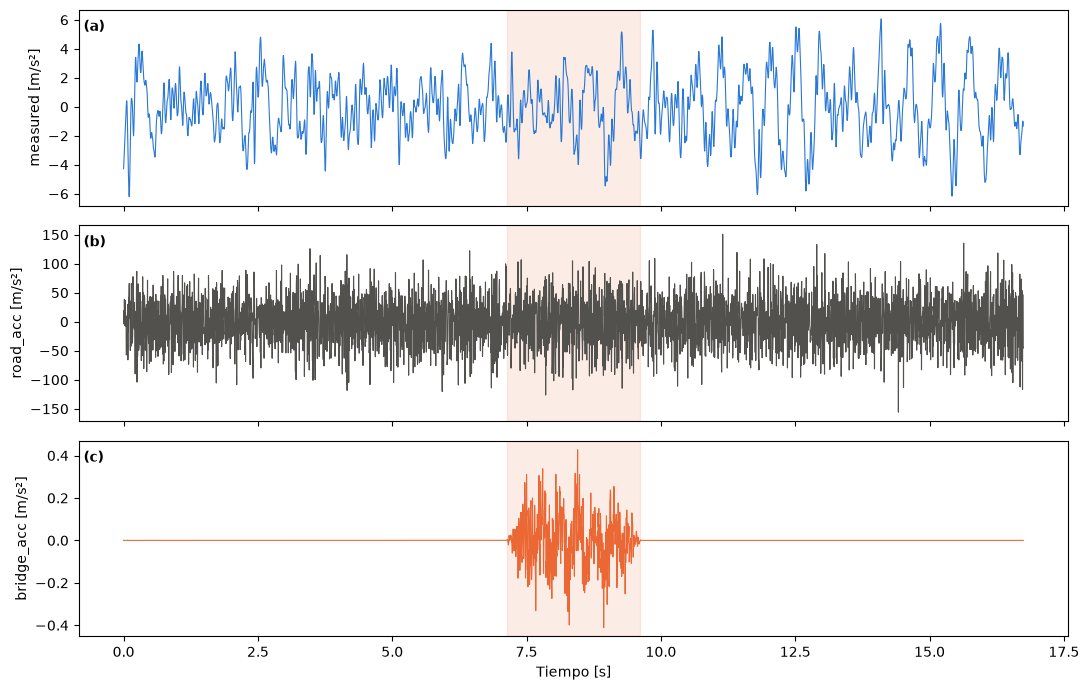

In [5]:
i = 6  # crossing to look at (change the number to see another one)
print(f"Crossing {i}: bridge {bridge_name[i]}, f1 = {f1[i]:.1f} Hz, speed = {speed[i]:.1f} m/s")

t = np.arange(n_samples) / FS        # time of each sample [s]
real = valid[i] == 1                 # real samples, without the padding
on_bridge = segment[i] == 1          # samples on the bridge

# Time when the car enters and leaves the bridge
t_enter = t[on_bridge][0]
t_leave = t[on_bridge][-1]

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
signals = [measured, road_acc, bridge_acc]
names = ["measured [m/s²]", "road_acc [m/s²]", "bridge_acc [m/s²]"]
colors = ["#2a78d6", "#52514e", "#eb6834"]
for ax, signal, name, color, letter in zip(axes, signals, names, colors, "abc"):
    ax.plot(t[real], signal[i][real], color=color, lw=0.8)
    ax.axvspan(t_enter, t_leave, color="#eb6834", alpha=0.12)   # time on the bridge
    ax.set_ylabel(name)
    ax.text(0.005, 0.95, f"({letter})", transform=ax.transAxes, va="top", fontweight="bold")
axes[-1].set_xlabel("Tiempo [s]")
plt.tight_layout()
plt.show()

**Figura 2.** Señales del viaje 6 (puente B3, f1 = 3.0 Hz, 14.0 m/s). (a) Aceleración medida por el teléfono. (b) Aceleración que la carretera le impone a la rueda. (c) Aceleración del puente bajo la rueda (salida de la red). La franja naranja marca el tiempo sobre el puente. Cada panel tiene su propia escala vertical.

Qué se ve:

- **(a) `measured`:** varía entre ±5 m/s² y se ve igual dentro y fuera del puente. A simple vista no se nota el puente.
- **(b) `road_acc`:** es unas 20 veces más grande que lo medido (±100 m/s²) y cambia muy rápido. Esos cambios rápidos casi no llegan al teléfono: el carro los atenúa.
- **(c) `bridge_acc`:** solo existe sobre el puente (fuera vale 0) y es unas 15 veces más pequeño que lo medido (±0.4 m/s²).

Una observación para la sección 4: `bridge_acc` vibra mucho más rápido que f1 = 3 Hz. Además del modo 1 contiene los modos 2 y 3 (12 y 27 Hz). En `bridge_acc`, el modo 1 es solo el 14–38 % de la energía según el puente, pero el carro casi no transmite los modos altos: de lo que llega al teléfono desde el puente, el modo 1 es el 95–99 %.

Para verlo directamente se compara `bridge_acc` con **la parte de la señal del teléfono que viene del puente**. El simulador guarda la señal del teléfono separada por fuente (puente, rugosidad, ruido), así que esa parte se puede leer del archivo. En un caso real no se tiene; aquí solo se usa para mirar, no como entrada de la red.

Se hace un zoom al tiempo sobre el puente (Figura 3).

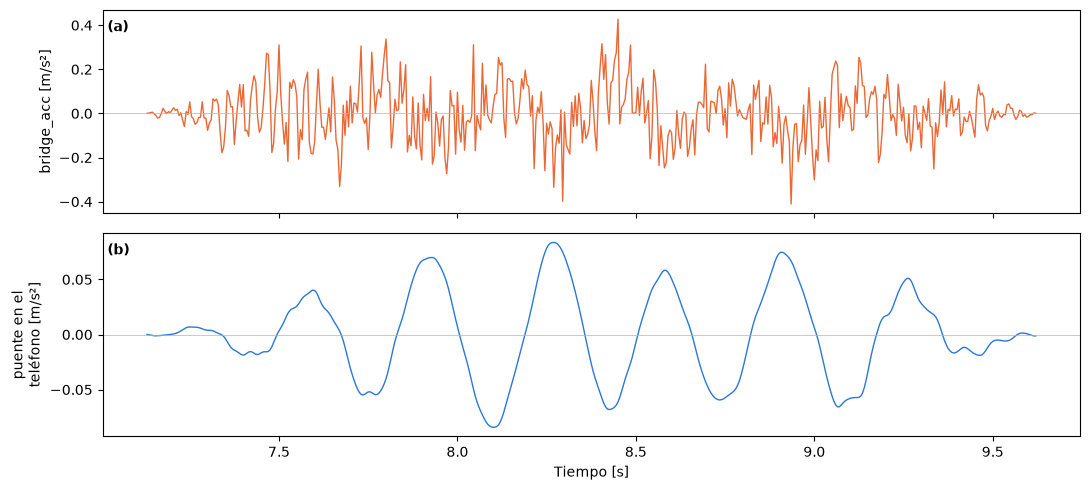

In [6]:
# Part of the phone signal that comes from the bridge (all its modes), only for crossing i
file = h5py.File(DATA_DIR / "main_padded.h5", "r")
bridge_in_phone = (file["components/bridge_mode_1"][i] + file["components/bridge_mode_2"][i]
                   + file["components/bridge_mode_3"][i] + file["components/bridge_higher_modes"][i])
file.close()

# Zoom: only the time on the bridge
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(t[on_bridge], bridge_acc[i][on_bridge], color="#eb6834", lw=1)
axes[0].set_ylabel("bridge_acc [m/s²]")
axes[1].plot(t[on_bridge], bridge_in_phone[on_bridge], color="#2a78d6", lw=1)
axes[1].set_ylabel("puente en el\nteléfono [m/s²]")
axes[1].set_xlabel("Tiempo [s]")
for ax, letter in zip(axes, "ab"):
    ax.axhline(0, color="0.7", lw=0.5)
    ax.text(0.005, 0.95, f"({letter})", transform=ax.transAxes, va="top", fontweight="bold")
plt.tight_layout()
plt.show()

**Figura 3.** Zoom al tiempo sobre el puente del viaje 6 (B3, f1 = 3.0 Hz). (a) Aceleración del puente bajo la rueda (`bridge_acc`). (b) Parte de la señal del teléfono que viene del puente. Cada panel tiene su propia escala vertical.

- **(a)** El puente vibra con una oscilación irregular y rápida: es la suma de sus modos 1, 2 y 3.
- **(b)** Lo que llega al teléfono es una oscilación suave de unos 3 Hz (un ciclo cada ~0.33 s), es decir, casi solo el modo 1. Es además unas 5 veces más pequeña, y aparece y desaparece al entrar y salir del puente.

## 4. Preparar la entrada y la salida de la red

La red recibe varias señales a la vez, como una foto recibe los tres colores (rojo, verde, azul). A cada señal de entrada se le llama **canal**. Aquí la red recibe 3 canales y devuelve 1 (Tabla 2).

**Tabla 2.** Entrada y salida de la red. Todas tienen 11 000 muestras por viaje.

| | Canal | Qué es | Por qué |
|---|---|---|---|
| Entrada | `measured` | lo que mide el teléfono | es la señal de la que se quiere sacar el puente |
| Entrada | `road_known` | `road_acc` con ceros sobre el puente | en un caso real, el perfil de la carretera se puede medir antes y después del puente, pero no sobre el puente |
| Entrada | `bridge_mask` | 1 sobre el puente, 0 fuera | le dice a la red dónde está el puente |
| Salida | `target` | `bridge_acc`, con todas sus frecuencias | es lo que la red debe devolver |

Las señales tienen tamaños muy distintos (`road_acc` ±100 m/s², `measured` ±5 m/s², `bridge_acc` ±0.4 m/s²). Se llevan a una escala parecida en la sección 5, con los datos de entrenamiento.

### 4.1 Entrada

`road_known` se obtiene multiplicando `road_acc` por `segment != 1`, que vale 1 fuera del puente y 0 sobre el puente.

`np.stack` junta los 3 canales en una sola tabla de 3 dimensiones: **viaje × canal × muestra**.

In [7]:
bridge_mask = (segment == 1).astype(np.float32)   # 1 on the bridge, 0 elsewhere
road_known = road_acc * (segment != 1)            # road input, set to 0 on the bridge

X = np.stack([measured, road_known, bridge_mask], axis=1)   # input of the network
print("X:", X.shape, "(crossings, channels, samples)")

X: (1000, 3, 11000) (crossings, channels, samples)


### 4.2 Salida

La salida es `bridge_acc` tal como viene del archivo, con todas sus frecuencias. Fuera del puente ya vale 0; al multiplicarla por la máscara se asegura que solo exista sobre el puente.

En la sección 3 se vio que el carro casi solo deja pasar el modo 1 del puente (Figura 3). Lo que no llega al teléfono no está en la entrada de la red. Por eso se espera que la red:

- recupere bien el modo 1, que es de donde sale f1;
- no recupere los modos altos ni el contenido rápido de `bridge_acc`.

Esto se comprobará en la sección 8, comparando el espectro de la salida de la red con el de `bridge_acc`.

**Prueba pendiente:** con estos datos la red solo puede recuperar f1, porque la rugosidad tapa los modos altos. Después se debe probar la red con datos sin rugosidad, para ver si es capaz de obtener todos los modos del puente.

In [8]:
target = bridge_acc * bridge_mask   # bridge acceleration under the wheel, only on the bridge

Y = target[:, np.newaxis, :]        # output of the network, with one channel
print("Y:", Y.shape, "(crossings, channels, samples)")

Y: (1000, 1, 11000) (crossings, channels, samples)


### 4.3 Ver la entrada y la salida de un viaje

Se grafican los 3 canales de entrada y la salida del mismo viaje de la sección 3 (Figura 4).

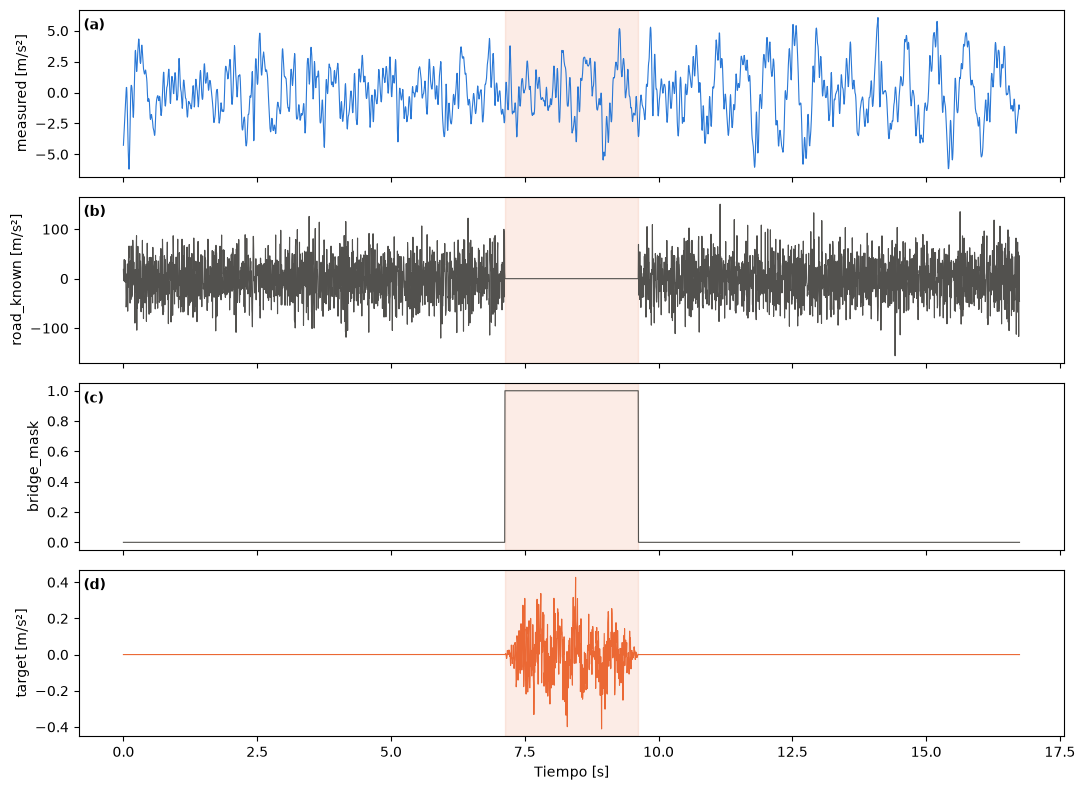

In [9]:
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
signals = [measured, road_known, bridge_mask, target]
names = ["measured [m/s²]", "road_known [m/s²]", "bridge_mask", "target [m/s²]"]
colors = ["#2a78d6", "#52514e", "#52514e", "#eb6834"]
for ax, signal, name, color, letter in zip(axes, signals, names, colors, "abcd"):
    ax.plot(t[real], signal[i][real], color=color, lw=0.8)
    ax.axvspan(t_enter, t_leave, color="#eb6834", alpha=0.12)   # time on the bridge
    ax.set_ylabel(name)
    ax.text(0.005, 0.95, f"({letter})", transform=ax.transAxes, va="top", fontweight="bold")
axes[-1].set_xlabel("Tiempo [s]")
plt.tight_layout()
plt.show()

**Figura 4.** Entrada y salida de la red para el viaje 6 (B3, f1 = 3.0 Hz). (a)–(c) Canales de entrada: aceleración medida, aceleración de la carretera con ceros sobre el puente y máscara del puente. (d) Salida: aceleración del puente bajo la rueda (`target`). La franja naranja marca el tiempo sobre el puente. Cada panel tiene su propia escala vertical.

Qué se ve:

- **(a) y (b):** fuera del puente la red recibe lo que mide el teléfono y lo que entra por la rueda. Con eso puede aprender cómo responde el carro.
- **(b) y (c):** sobre el puente, `road_known` vale 0 y la máscara vale 1. La red sabe dónde está el puente, pero no qué pisa la rueda ahí.
- **(d):** la salida es la misma aceleración del puente de la Figura 2c: solo existe sobre el puente y fuera vale 0.

## 5. Dividir en entrenamiento, validación y prueba

Los viajes se separan en tres grupos, cada uno con un papel distinto:

- **Entrenamiento (70 %):** la red aprende con estos viajes.
- **Validación (15 %):** durante el entrenamiento se revisa cómo le va a la red con estos viajes, que no usa para aprender. Sirve para ver si mejora de verdad o solo memoriza los de entrenamiento, y para decidir cuándo parar.
- **Prueba (15 %):** no se tocan hasta el final (sección 8). Dan la nota final de la red.

La división se hace **por puente**: de los 200 viajes de cada puente, 140 van a entrenamiento, 30 a validación y 30 a prueba. Así los 5 puentes están en los tres grupos. La prueba con puentes que la red nunca vio se hace aparte, con el paquete G1–G5 (sección 10).

### 5.1 Dividir los viajes

Para cada puente se buscan sus viajes (`np.where`), se revuelven al azar (`rng.permutation`, con la semilla fija para que siempre salga igual) y se reparten en orden: los primeros 140 a entrenamiento, los 30 siguientes a validación y el resto a prueba.

In [10]:
rng = np.random.default_rng(SEED)
train_idx, val_idx, test_idx = [], [], []   # numbers of the crossings of each group

for name in np.unique(bridge_name):
    idx = np.where(bridge_name == name)[0]   # crossings of this bridge
    idx = rng.permutation(idx)               # shuffle them
    n_train = int(0.70 * len(idx))           # 140
    n_val = int(0.15 * len(idx))             # 30
    train_idx += list(idx[:n_train])
    val_idx += list(idx[n_train:n_train + n_val])
    test_idx += list(idx[n_train + n_val:])

train_idx = np.array(train_idx)
val_idx = np.array(val_idx)
test_idx = np.array(test_idx)

**Tabla 3.** Número de viajes de cada puente en cada grupo.

In [11]:
print("Bridge  f1 [Hz]  train  val  test")
for name in np.unique(bridge_name):
    n_train = np.sum(bridge_name[train_idx] == name)
    n_val = np.sum(bridge_name[val_idx] == name)
    n_test = np.sum(bridge_name[test_idx] == name)
    print(f"{name:6}  {f1[bridge_name == name][0]:7.1f}  {n_train:5}  {n_val:3}  {n_test:4}")
print(f"Total            {len(train_idx):5}  {len(val_idx):3}  {len(test_idx):4}")

Bridge  f1 [Hz]  train  val  test
B1          8.0    140   30    30
B2          4.5    140   30    30
B3          3.0    140   30    30
B4          2.3    140   30    30
B5          1.6    140   30    30
Total              700  150   150


Cada puente queda con 140 / 30 / 30 viajes. Ningún viaje está en dos grupos a la vez.

### 5.2 Llevar las señales a una escala parecida

Las señales tienen tamaños muy distintos: `road_acc` llega a ±100 m/s², `measured` a ±5 m/s² y `bridge_acc` a ±0.4 m/s². Una red aprende mejor cuando todos sus números son de un tamaño parecido, cerca de 1. Si no, la señal grande domina y la pequeña casi no se nota.

Cada señal se divide por su **desviación estándar** $\sigma$, que mide cuánto se aleja la señal de cero en promedio:

$$x_{\text{escalada}} = \frac{x}{\sigma} \tag{1}$$

- $x$: la señal en m/s².
- $\sigma$: su desviación estándar en m/s², calculada **solo con los viajes de entrenamiento**.
- $x_{\text{escalada}}$: la señal sin unidades, que se mueve más o menos entre −5 y 5.

Se usan solo los viajes de entrenamiento para que la red no reciba ninguna información de los viajes de validación y prueba. Cada $\sigma$ se calcula con las muestras donde la señal existe:

- `measured`: todas las muestras reales (sin el relleno).
- `road_known`: las muestras reales fuera del puente (sobre el puente vale 0 a propósito).
- `target`: las muestras sobre el puente (fuera vale 0).
- `bridge_mask` no se escala: ya vale 0 o 1.

In [12]:
# Samples of the training crossings used to compute each scale
train_real = valid[train_idx] == 1                           # real samples (no padding)
train_off_bridge = train_real & (segment[train_idx] != 1)    # real samples off the bridge
train_on_bridge = segment[train_idx] == 1                    # samples on the bridge

scale_measured = measured[train_idx][train_real].std()
scale_road = road_known[train_idx][train_off_bridge].std()
scale_target = target[train_idx][train_on_bridge].std()

print(f"scale_measured = {scale_measured:.3f} m/s^2")
print(f"scale_road     = {scale_road:.3f} m/s^2")
print(f"scale_target   = {scale_target:.4f} m/s^2")

scale_measured = 0.764 m/s^2
scale_road     = 23.673 m/s^2
scale_target   = 0.0899 m/s^2


Se divide cada canal por su escala y luego se separan los tres grupos. `scale_target` se guarda: en la sección 8 se usa para pasar la salida de la red de vuelta a m/s².

In [13]:
X_scaled = X.copy()
X_scaled[:, 0, :] = X[:, 0, :] / scale_measured   # measured
X_scaled[:, 1, :] = X[:, 1, :] / scale_road       # road_known
# channel 2 (bridge_mask) stays as it is: 0 or 1
Y_scaled = Y / scale_target                       # target

X_train, Y_train = X_scaled[train_idx], Y_scaled[train_idx]
X_val, Y_val = X_scaled[val_idx], Y_scaled[val_idx]
X_test, Y_test = X_scaled[test_idx], Y_scaled[test_idx]

print("Train:", X_train.shape, Y_train.shape)
print("Val:  ", X_val.shape, Y_val.shape)
print("Test: ", X_test.shape, Y_test.shape)

Train: (700, 3, 11000) (700, 1, 11000)
Val:   (150, 3, 11000) (150, 1, 11000)
Test:  (150, 3, 11000) (150, 1, 11000)


Para ver el efecto se grafican las señales escaladas del mismo viaje de antes (Figura 5). Los tres paneles comparten el eje vertical.

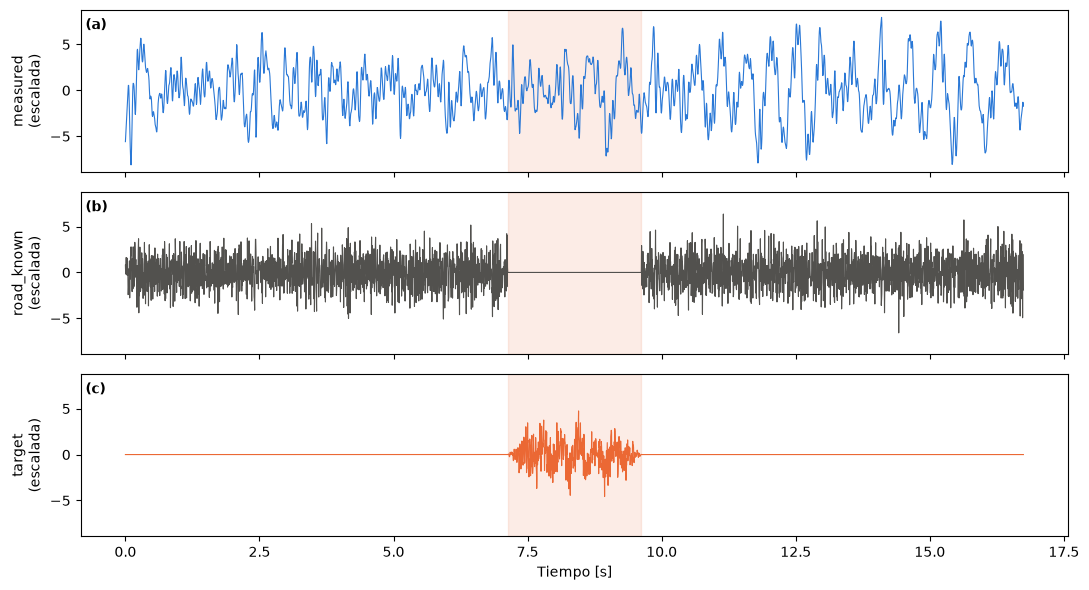

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True, sharey=True)
signals = [X_scaled[i, 0], X_scaled[i, 1], Y_scaled[i, 0]]
names = ["measured\n(escalada)", "road_known\n(escalada)", "target\n(escalada)"]
colors = ["#2a78d6", "#52514e", "#eb6834"]
for ax, signal, name, color, letter in zip(axes, signals, names, colors, "abc"):
    ax.plot(t[real], signal[real], color=color, lw=0.8)
    ax.axvspan(t_enter, t_leave, color="#eb6834", alpha=0.12)   # time on the bridge
    ax.set_ylabel(name)
    ax.text(0.005, 0.95, f"({letter})", transform=ax.transAxes, va="top", fontweight="bold")
axes[-1].set_xlabel("Tiempo [s]")
plt.tight_layout()
plt.show()

**Figura 5.** Señales escaladas del viaje 6 (B3). (a) Aceleración medida. (b) Aceleración de la carretera con ceros sobre el puente. (c) Salida de la red. Los tres paneles tienen la misma escala vertical. La franja naranja marca el tiempo sobre el puente.

Qué se ve: después de escalar, las tres señales tienen un tamaño parecido, aunque antes `road_acc` era unas 260 veces más grande que `bridge_acc` (23.7 contra 0.09 m/s² de desviación estándar). Ninguna señal domina a las otras al entrar a la red.